# Question 2 — Classification benchmark
**Dataset:** Fisher Iris dataset registered at [OpenML ID 61 (v1)](https://www.openml.org/d/61), with 150 observations, 4 numeric attributes and 3 species classes.

**Provenance / offline transparency:** In this prepared submission the bundled CSV uses the Fisher Iris copy distributed with scikit-learn, corresponding to the OpenML-listed dataset. We could not download OpenML live in the execution environment. To request a direct download on a machine with network access, run `python -m src.q2_classification --use-openml-live`. The default notebook uses the bundled offline copy so all experiments can be reproduced without internet.

**Design:** Remove exact duplicates, handle invalid/missing numeric values, visualize, stratified hold-out split (70/30), impute and scale within a train-only pipeline, compare 13 classifiers with 5-fold train-only cross-validation, then inspect held-out metrics. Decision Tree complexity demonstrates overfitting.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image,display
from src.q2_classification import main,get_data,FEATURES
root=Path.cwd()
df,origin=get_data(root)
print('Origin:',origin)
print('Raw shape:',df.shape)
print('Class counts:')
print(df['class'].value_counts())
print('Missing numeric cells:',df[FEATURES].isna().sum().sum(),'Exact duplicates:',df.duplicated().sum())
display(df.head())

Origin: Bundled offline mirror (scikit-learn Fisher Iris); OpenML dataset 61
Raw shape: (150, 5)
Class counts:
class
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64
Missing numeric cells: 0 Exact duplicates: 1


,sepallength,sepalwidth,petallength,petalwidth,class
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Preprocessing and visual exploration
Raw observations are examined before splitting, but numeric imputation and standardization are fitted **only on training folds** during cross-validation, preventing feature-statistic leakage.

Q2 successful: train-only stratified CV, final held-out test evaluation.
               model  cv_macro_f1_mean  cv_macro_f1_std  train_accuracy  test_accuracy  test_precision_macro  test_recall_macro  test_f1_macro  train_test_accuracy_gap
Gaussian Naive Bayes             0.981            0.023           0.981          0.911                 0.916              0.911          0.911                    0.070
          Linear SVM             0.981            0.023           0.981          0.867                 0.871              0.867          0.868                    0.114
 Logistic Regression             0.981            0.023           0.981          0.911                 0.916              0.911          0.911                    0.070
         Extra Trees             0.971            0.038           1.000          0.911                 0.916              0.911          0.911                    0.089
                 LDA             0.971            0.038           0.981          0.978 

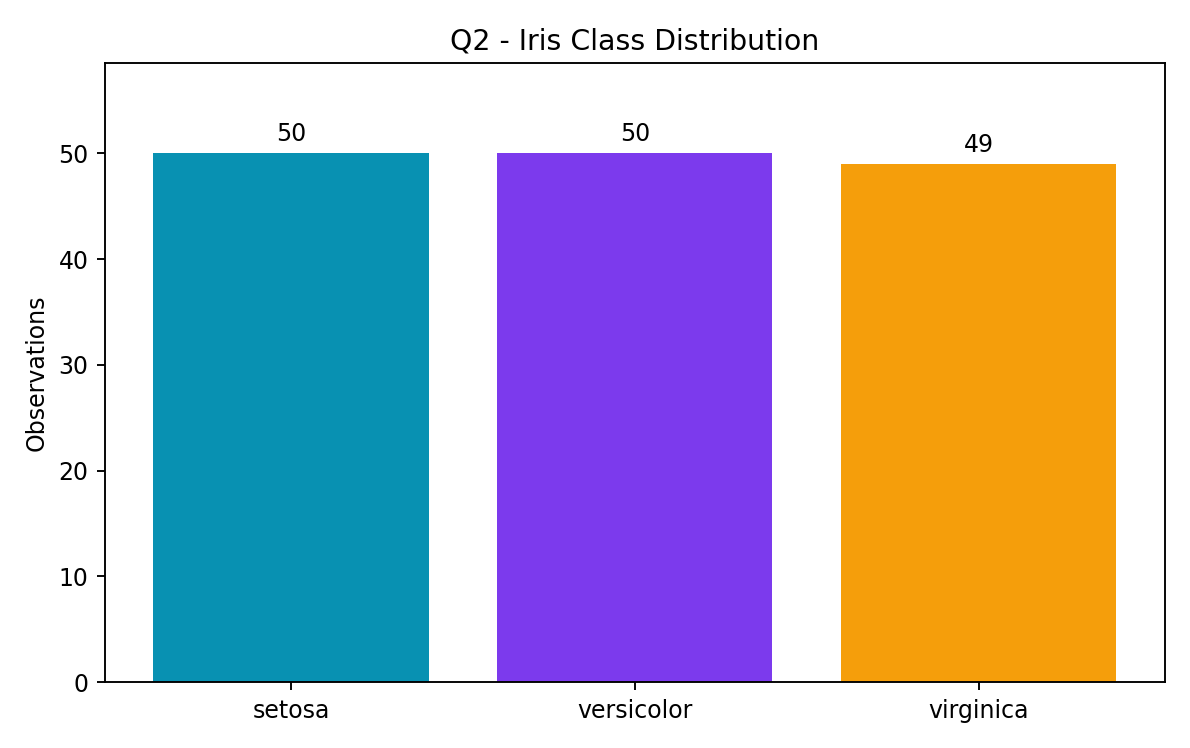

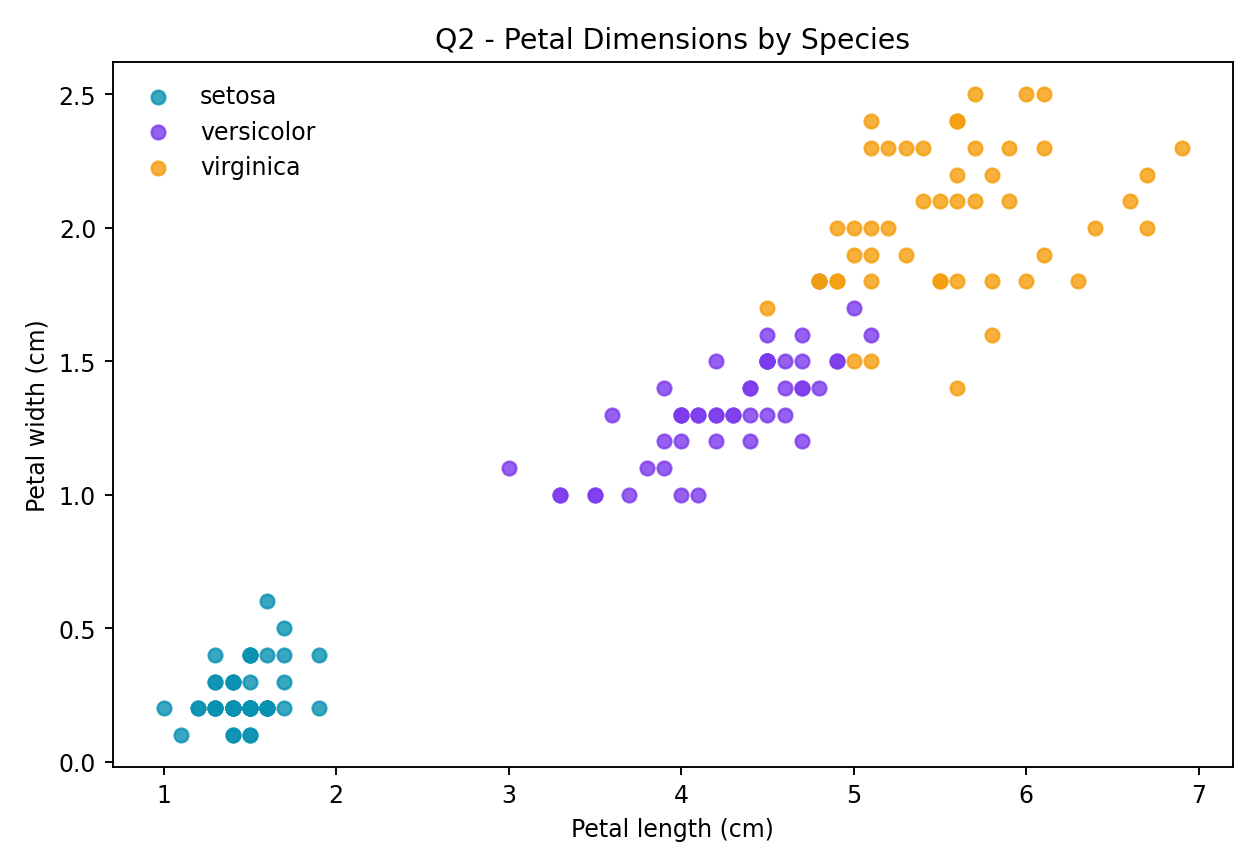

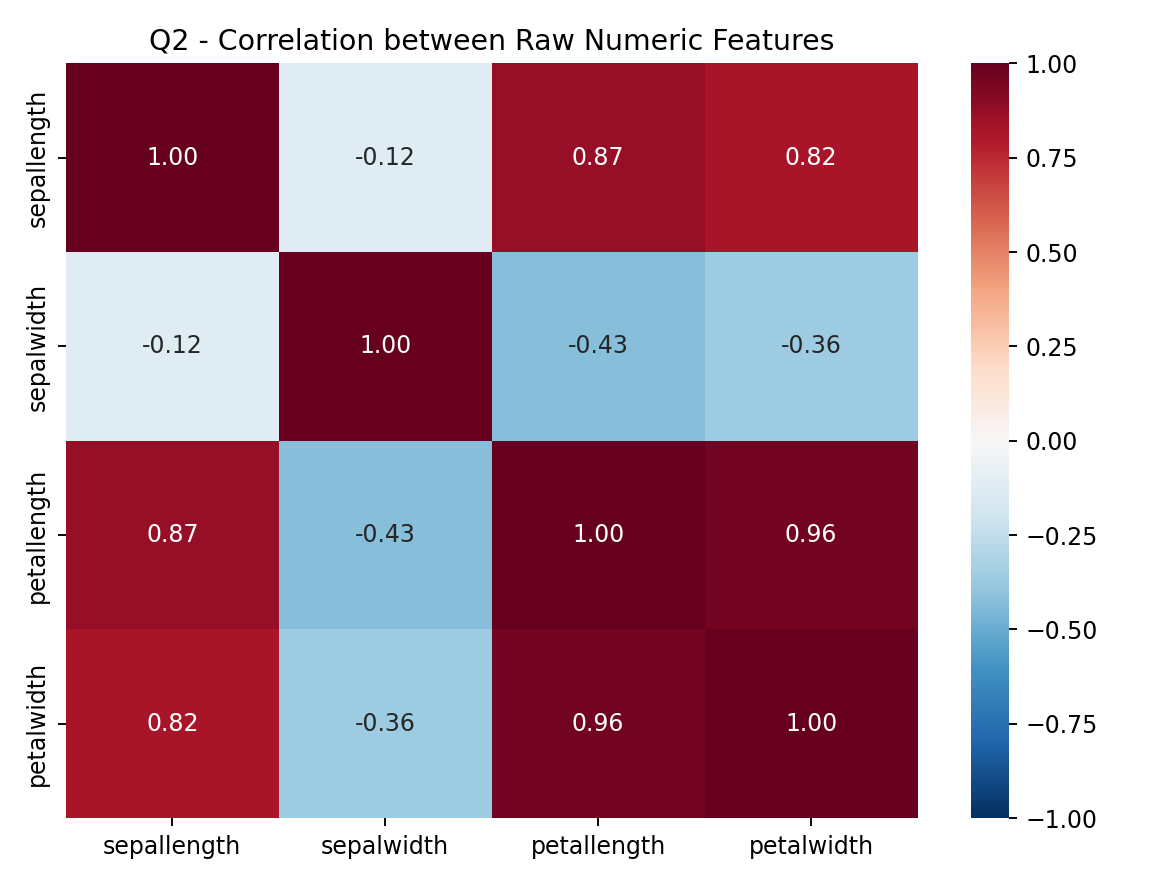

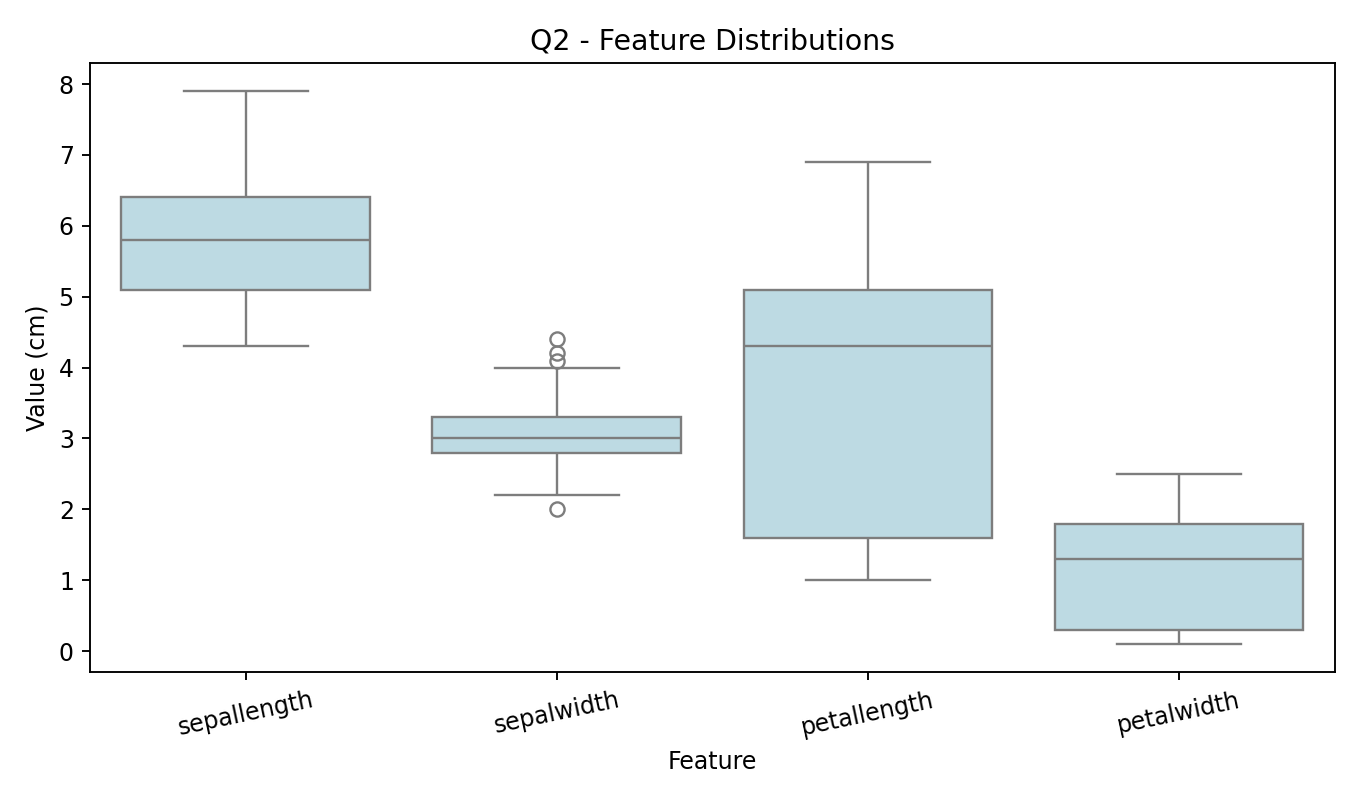

In [2]:
summary,comparison=main(root)
for filename in ['q2_class_balance.png','q2_feature_scatter.png','q2_correlation.png','q2_feature_distributions.png']:
    display(Image(filename=str(root/'figures'/filename),width=540))

## Classifiers and test evaluation
The champion was selected from 5-fold CV macro-F1 computed **on training data only**, not from the test performance. This distinction avoids test-driven model selection.

,model,cv_macro_f1_mean,cv_macro_f1_std,train_accuracy,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,train_test_accuracy_gap
0,Gaussian Naive Bayes,0.9809,0.0234,0.9808,0.9111,0.9155,0.9111,0.9107,0.0697
1,Linear SVM,0.9809,0.0234,0.9808,0.8667,0.8708,0.8667,0.8681,0.1141
2,Logistic Regression,0.9809,0.0234,0.9808,0.9111,0.9155,0.9111,0.9107,0.0697
3,Extra Trees,0.9714,0.0381,1.0000,0.9111,0.9155,0.9111,0.9107,0.0889
4,LDA,0.9714,0.0381,0.9808,0.9778,0.9792,0.9778,0.9778,0.0030
5,SVM (RBF),0.9714,0.0381,0.9712,0.9111,0.9155,0.9111,0.9107,0.0600
6,QDA,0.9713,0.0234,0.9808,0.9778,0.9792,0.9778,0.9778,0.0030
7,KNN (k=5),0.9703,0.0243,0.9808,0.9111,0.9298,0.9111,0.9095,0.0697
8,Gradient Boosting,0.9609,0.0372,1.0000,0.9333,0.9345,0.9333,0.9333,0.0667
9,AdaBoost,0.9521,0.0524,1.0000,0.9333,0.9345,0.9333,0.9333,0.0667


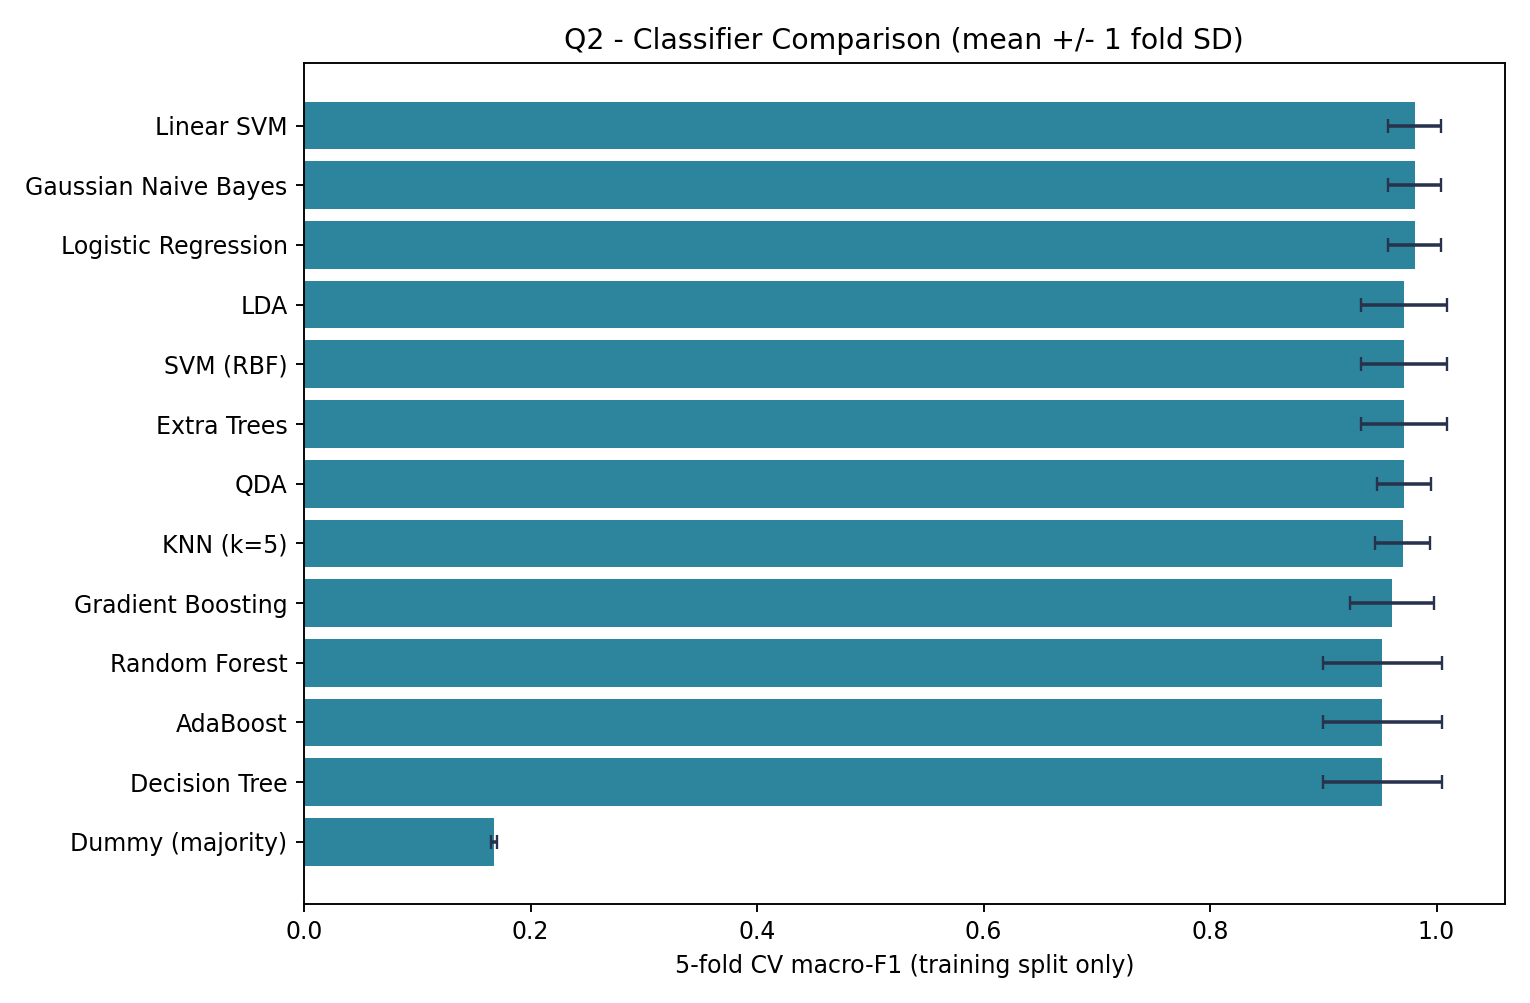

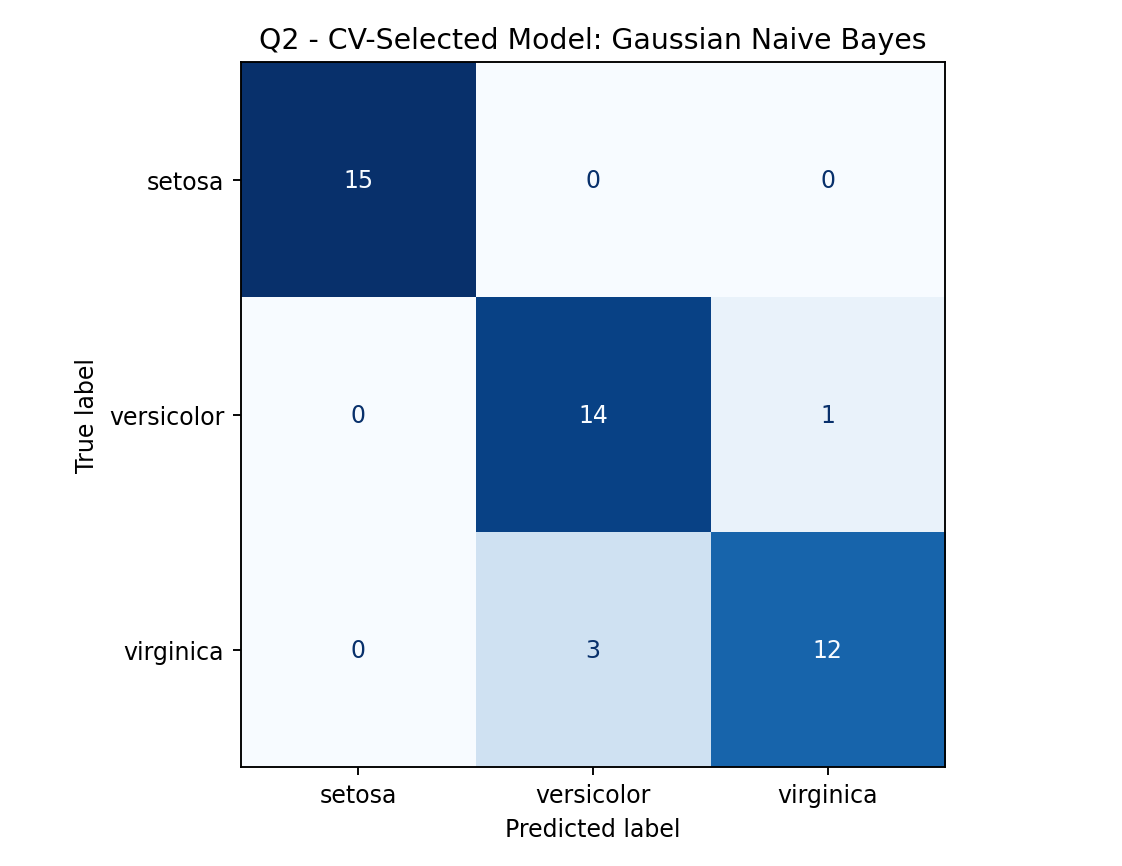

Selected classifier: Gaussian Naive Bayes
Hold-out accuracy: 0.9111
Hold-out macro-F1: 0.9107


In [3]:
display(comparison.round(4))
display(Image(filename=str(root/'figures/q2_model_comparison.png'),width=720))
display(Image(filename=str(root/'figures/q2_champion_confusion.png'),width=520))
print('Selected classifier:',summary['champion_selected_by_train_cv'])
print('Hold-out accuracy:',round(summary['champion_test_accuracy'],4))
print('Hold-out macro-F1:',round(summary['champion_test_macro_f1'],4))

## Overfitting and mitigation
A depth-unlimited Decision Tree can memorize the training set. Compare its training macro-F1 with cross-validation scores. Limit `max_depth` using training CV rather than looking at test accuracy; this is pre-pruning. Further ways to reduce overfitting: minimum leaf size, cost-complexity pruning (`ccp_alpha`), fewer features, more data, and regularization appropriate to the algorithm.

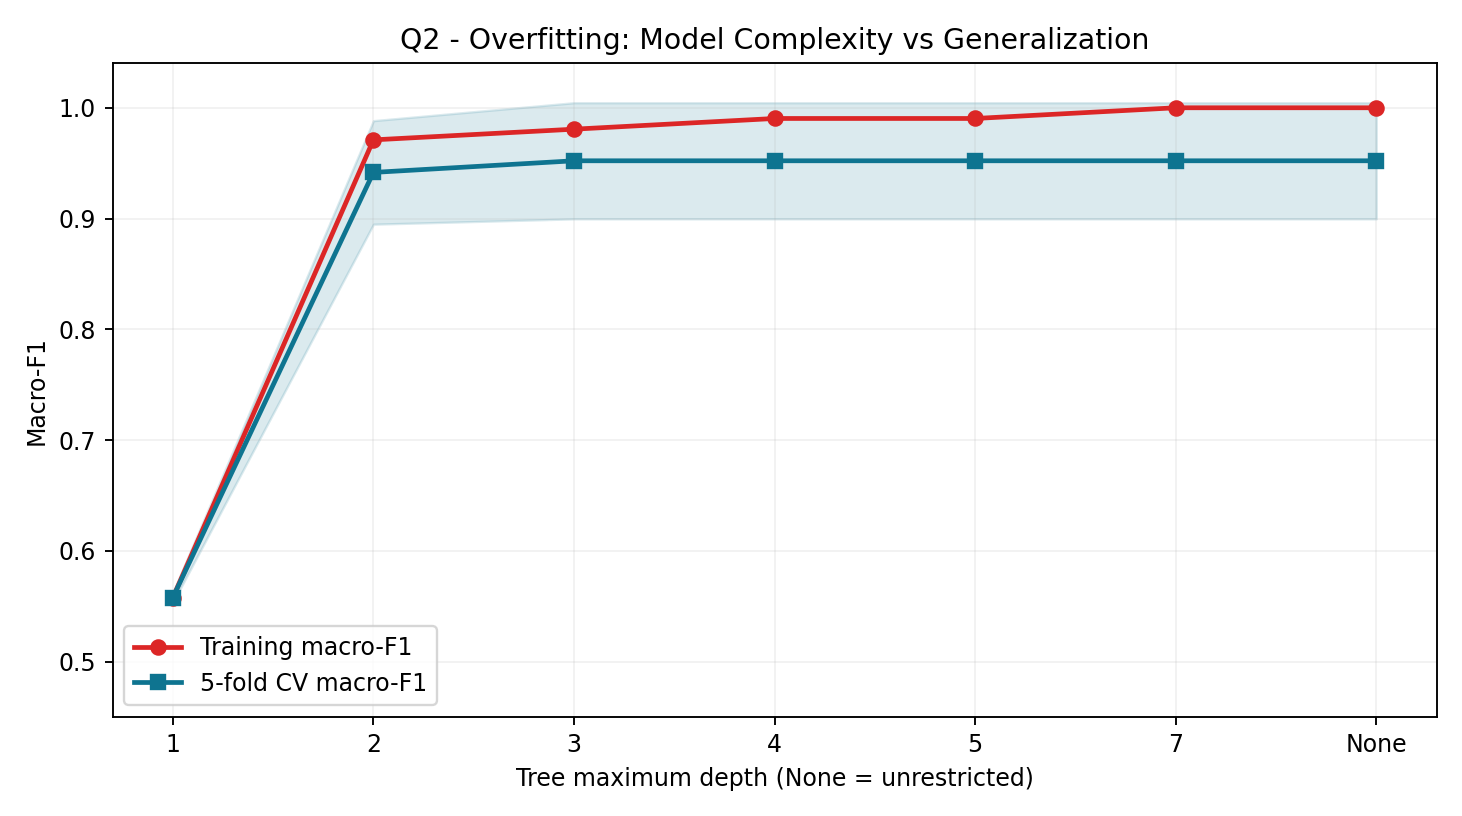

,max_depth,train_macro_f1,cv_macro_f1,cv_std
0,1.0,0.557692,0.557778,0.004444
1,2.0,0.971014,0.941632,0.046743
2,3.0,0.980672,0.952137,0.052432
3,4.0,0.990330,0.952137,0.052432
4,5.0,0.990330,0.952137,0.052432
5,7.0,1.000000,0.952137,0.052432
6,NaN,1.000000,0.952137,0.052432


Mitigation comparison: {'selected_max_depth_using_cv': '3', 'unpruned_train_macro_f1': 1.0, 'unpruned_test_macro_f1': 0.9111111111111111, 'pruned_train_macro_f1': 0.9806722689075631, 'pruned_test_macro_f1': 0.9326599326599326, 'important_note': 'Depth selected with training CV only; both held-out test scores reported after selection.'}


In [4]:
display(Image(filename=str(root/'figures/q2_overfitting.png'),width=710))
display(pd.read_csv(root/'results/q2_tree_depth_study.csv'))
print('Mitigation comparison:',summary['overfitting_mitigation'])

## Findings and limitations
The Iris task is relatively simple and the test set is small, so ranking by a single hold-out split is unstable. A high test score for one candidate is not evidence it should replace the CV-selected champion. Mean and standard deviation of 5 training folds give a more defensible comparison. The local copy is explicitly a mirror, not a recorded OpenML download; see the dataset link and optional live-fetch command for provenance verification.